In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy import stats

In [2]:
data = pd.read_csv('final_dataset_90.csv')
print(data)

    Obs          State  IncomeClass  Attainment   Cost   Aid  n_cps
0     1        Alabama            0        40.2  11888   290  161.0
1     2        Alabama            1        25.6  11888   290  161.0
2     3         Alaska            0        40.5   9081   890  150.0
3     4         Alaska            1        11.4   9081   890   76.0
4     5        Arizona            0        44.5  12585   220  193.0
..  ...            ...          ...         ...    ...   ...    ...
85   86       Virginia            1        32.7  15217  2440  103.0
86   87  West Virginia            0        29.4   9225  1250  157.0
87   88  West Virginia            1        13.6   9225  1250  114.0
88   89      Wisconsin            0        47.2   9693   570  142.0
89   90      Wisconsin            1        23.5   9693   570   89.0

[90 rows x 7 columns]


In [3]:
# Method 1: Linear Regression with OLS
# Model equation: Attainment = β0 + β1(Cost) + β2(Financial Aid) + β3(Income class) + ϵ

X = pd.DataFrame(data, columns=['IncomeClass', 'Cost', 'Aid'])
y = pd.Series(data['Attainment'])

X = X[['Cost', 'Aid', 'IncomeClass']]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())
print(f"\nRegression F-Statistic: {model.fvalue:.4f}")
print(f"Prob (F-statistic): {model.f_pvalue:.4e}")
print("Degrees of Freedom: 86")

                            OLS Regression Results                            
Dep. Variable:             Attainment   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     90.07
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.88e-26
Time:                        22:05:42   Log-Likelihood:                -306.78
No. Observations:                  90   AIC:                             621.6
Df Residuals:                      86   BIC:                             631.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          38.7428      3.443     11.254      

In [4]:
# Method 2: Linear Regression with a train/split test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model_2 = LinearRegression()
model_2.fit(X_train, y_train)

print("Intercept:", model_2.intercept_)
print("Coefficients:", model_2.coef_)
print("R^2:", model_2.score(X_train, y_train))
# print("T-Test:", stats.ttest_ind(X_test, y_test))

Intercept: 38.70252805347163
Coefficients: [ 0.00000000e+00  1.02973366e-03 -3.16192001e-04 -2.61336054e+01]
R^2: 0.7754413114698582


In [5]:
# Descriptive Statistics
print("Descriptive statistics of X variables", X.describe(), "\n")
print("Descriptive statistics of Y expected", y.describe())

Descriptive statistics of X variables        const          Cost          Aid  IncomeClass
count   90.0     90.000000    90.000000    90.000000
mean     1.0  11551.155556  1046.444444     0.500000
std      0.0   2932.867745   869.573460     0.502801
min      1.0   6362.000000    20.000000     0.000000
25%      1.0   9225.000000   470.000000     0.000000
50%      1.0  10819.000000   890.000000     0.500000
75%      1.0  13560.000000  1250.000000     1.000000
max      1.0  17284.000000  3960.000000     1.000000 

Descriptive statistics of Y expected count    90.000000
mean     36.845556
std      14.968522
min      10.400000
25%      24.650000
50%      35.150000
75%      47.650000
max      72.500000
Name: Attainment, dtype: float64


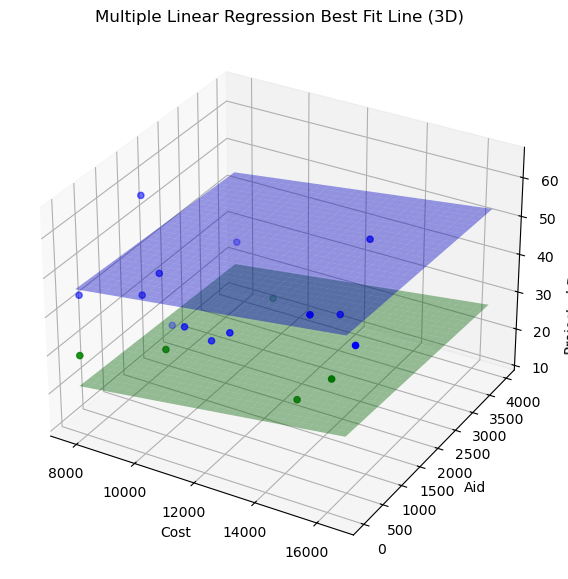

In [6]:
# Making predictions and visualize with a 3-D space
y_pred = model.predict(X_test)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

for cls, color, label in [(0, 'blue', 'Actual: higher income (0)'),
                          (1, 'green', 'Actual: lower income (1)')]:
    mask = (X_test['IncomeClass'] == cls).values
    
    ax.scatter(X_test.loc[mask, 'Cost'], X_test.loc[mask, 'Aid'],
           np.asarray(y_test)[mask], color=color, label=label)

x1_range = np.linspace(X_test['Cost'].min(), X_test['Cost'].max(), 30)
x2_range = np.linspace(X_test['Aid'].min(), X_test['Aid'].max(), 30)
x1, x2 = np.meshgrid(x1_range, x2_range)

for cls, color in [(0, 'blue'), (1, 'green')]:
    grid = pd.DataFrame({'const': 1.0,
                         'Cost': x1.ravel(),
                         'Aid': x2.ravel(),
                         'IncomeClass': cls})
    
    z = model.predict(grid[X_test.columns]).to_numpy().reshape(x1.shape)
    ax.plot_surface(x1, x2, z, color=color, alpha=0.4)

ax.set_xlabel('Cost')
ax.set_ylabel('Aid')
ax.set_zlabel('Projected Degree Attainment')
ax.set_title('Multiple Linear Regression Best Fit Line (3D)')

plt.show()

In [7]:
# All data values after analysis
print(f"Intercept: {model.params['const']:.4f} (SE {model.bse['const']:.4f}) [t {model.tvalues['const']:.2f}]")
for v in ["Cost", "Aid", "IncomeClass"]:
    print(f"{v}: {model.params[v]:.5f} (SE {model.bse[v]:.5f}) [t {model.tvalues[v]:.2f}]")

print(f"R2 = {model.rsquared:.4f} Adj R2 = {model.rsquared_adj:.2f}")
print(f"F({int(model.df_model)}, {int(model.df_resid)}) = {model.fvalue:.2f}")
print(f"N = {int(model.nobs)} D.F. = {int(model.df_resid)} DW = {durbin_watson(model.resid):.2f}")

Intercept: 38.7428 (SE 3.4427) [t 11.25]
Cost: 0.00097 (SE 0.00027) [t 3.60]
Aid: -0.00048 (SE 0.00091) [t -0.53]
IncomeClass: -25.28667 (SE 1.57733) [t -16.03]
R2 = 0.7586 Adj R2 = 0.75
F(3, 86) = 90.07
N = 90 D.F. = 86 DW = 1.73


In [8]:
# Creating the Appendices
# Appendix A: Raw Computer Output
with open("regression_output.txt", "w") as f:
    f.write(model.summary().as_text())
print(model.summary())

# Appendix B: OLS Regression Results
table = data[["State", "IncomeClass", "Attainment", "Cost", "Aid"]].copy()
table.insert(0, "Obs", range(1, len(table) + 1))
table.to_excel("appendix_b_data.xlsx", index=False)
print("Table successfully made into an excel file.")

# Note: The sources are on a separate sheet from Appendix A.

                            OLS Regression Results                            
Dep. Variable:             Attainment   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     90.07
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.88e-26
Time:                        22:05:42   Log-Likelihood:                -306.78
No. Observations:                  90   AIC:                             621.6
Df Residuals:                      86   BIC:                             631.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          38.7428      3.443     11.254      